In [18]:
# Local peptide apis
import functools
import ast
import pickle
from logging import getLogger
from pathlib import Path
from typing import Callable
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, RDKFingerprint
from rdkit.Chem.AllChem import GetMorganGenerator
from mordred import Calculator, descriptors
from PIL import Image as PILImage
import re

import numpy as np
import pandas as pd
import math
from src.args import get_args
from src.peptide_fw import *
from benchmark_pepfw import *
from src.api import peptide_api
from src.sequence.alignment import align_helm

import matplotlib.pyplot as plt
import seaborn as sns

import json
import random
import time
import optuna
from sklearn.linear_model import ElasticNet, BayesianRidge, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR, LinearSVR
from sklearn.metrics import mean_squared_error
import xgboost as xgb
from paper_dataset_config import DATASET_SETTINGS_UPDATE, refid_all

In [19]:
output_dir = './results/paper/'

output_dir_example = f'{output_dir}/example/'
output_dir_pred_time = f'{output_dir}/pred_time/'

In [35]:
coef_df = pd.read_csv(f'{output_dir_example}/fwfp_coef.csv')
monomer_db_path = 'regmol_db_update_filt.csv'
monomer_db = pd.read_csv(monomer_db_path)
monomer_db_list = monomer_db['symbol'].tolist()
total_sequences = 1
for i in range(0, 14):
    coef_tmp = coef_df[coef_df['pos'] == i]
    # get the unique elements in 'mono' that are also in monomer_db_list
    unique_monos = coef_tmp[coef_tmp['mono'].isin(monomer_db_list)]['mono'].unique()
    print(f"Position {i}: {len(unique_monos)} unique monomers")
    total_sequences *= len(unique_monos)

print(f"Total number of possible sequences in the example dataset: {total_sequences:e}")

Position 0: 38 unique monomers
Position 1: 10 unique monomers
Position 2: 18 unique monomers
Position 3: 60 unique monomers
Position 4: 30 unique monomers
Position 5: 21 unique monomers
Position 6: 12 unique monomers
Position 7: 5 unique monomers
Position 8: 94 unique monomers
Position 9: 32 unique monomers
Position 10: 66 unique monomers
Position 11: 26 unique monomers
Position 12: 19 unique monomers
Position 13: 11 unique monomers
Total number of possible sequences in the example dataset: 1.673557e+19


In [1]:
print(f"The entire design space: {4000**14:e}")
print(f"The design space with selected AAs: {50**14:e}")


The entire design space: 2.684355e+50
The design space with selected AAs: 6.103516e+23


In [ ]:
# construct the time results in a pd
num_total_peptides = [total_sequences, 4000**14, 50**14]

for model_type in ['svr', 'rf', 'xgboost', 'bayesian_ridge', 'FW']:
    # load the prediction time results 
    time_df = pd.read_csv(os.path.join(output_dir_pred_time, f"{target_name}_prediction_time_{model_type}.csv"))
    # extract the rows in time_df with the model_type
    time_df = time_df[time_df['model'] == model_type]

    from sklearn.linear_model import LinearRegression
    X = time_df["num_samples"].values.reshape(-1, 1)
    y = time_df["test_time"].values
    reg = LinearRegression().fit(X, y)
    # predict for larger Num of samples
    X_pred = np.array(num_total_peptides).reshape(-1, 1)
    y_pred = reg.predict(X_pred)
    print(f"Model: {model_type}; {y_pred/3600/24/365} years")

Model: svr; [1.29266539e+11 8.03652422e+39 2.72357413e+14] years
Model: rf; [4.00546136e+08 2.49020260e+37 8.43928445e+11] years
Model: xgboost; [1.18470760e+09 7.36534864e+37 2.49611305e+12] years
Model: bayesian_ridge; [1.16803096e+09 7.26166972e+37 2.46097632e+12] years
Model: FW; [5.29310409e+06 3.29073243e+35 1.11522761e+10] years


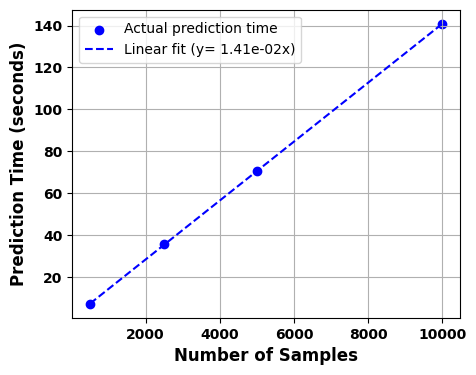

In [31]:
for model_type in ['svr', 'rf', 'xgboost', 'FW']:
    # load the prediction time results 
    time_df = pd.read_csv(os.path.join(output_dir_pred_time, f"{target_name}_prediction_time_{model_type}.csv"))
    # extract the rows in time_df with the model_type
    time_df = time_df[time_df['model'] == model_type]

    from sklearn.linear_model import LinearRegression
    x = time_df["num_samples"].values.reshape(-1, 1)
    y = time_df["test_time"].values
    reg = LinearRegression().fit(x, y)

    # make a plot where x is Num samples, y is Test time (seconds)
    # use log scale for x and y axes
    plt.figure(figsize=(5, 4))
    # plot the predicted points together with the original points
    # solid line for original points, dashed line for predicted points
    plt.scatter(x, y, color='blue', label='Actual prediction time')
    plt.plot(x, reg.predict(x), color='blue', label=f'Linear fit (y= {reg.coef_[0]:.2e}x)', linestyle='--')
    plt.legend()
    plt.xlabel("Number of Samples", fontsize=12, fontweight='bold')
    plt.ylabel("Prediction Time (seconds)", fontsize=12, fontweight='bold')
    # xticks = [500, 2500, 5000, 10000]
    # plt.xticks(xticks, fontsize=10, fontweight='bold')
    # set tick size
    plt.xticks(fontsize=10, fontweight='bold')
    plt.yticks(fontsize=10, fontweight='bold')
    plt.grid(True)
    # in log scale
    # plt.xscale('log')
    # plt.yscale('log')
    # plt.title(f"Prediction Time vs Number of Samples for {model_type} Model")